# Projet de synthèse — Prédiction de la maladie cardiaque (UCI Heart Disease)

**Module :** Introduction à Python, analyse de données et Machine Learning  
**Secteur :** Santé (cardiologie)  
**Étudiants (groupe) :** Faker BEN NOOMEN, Haythem BEN BOUBAKER, Mariem DRIDI  
**Tâche prévue :** Classification binaire supervisée — prédire si un patient a une **maladie cardiaque : Oui (1) ou Non (0)**

## A. Présentation et compréhension (contexte, idée, problématique, données)

### Contexte métier et idée
Les maladies cardiovasculaires sont une cause majeure de morbidité et de mortalité. À partir de données cliniques de routine (symptômes, mesures, ECG, épreuve d’effort), l’idée est de construire un outil **d’aide à la décision** pour estimer le risque de présence d’une maladie cardiaque et aider au dépistage / à la priorisation des examens.

### Question / problématique métier
**Peut-on prédire la présence d’une maladie cardiaque à partir de variables cliniques de routine, afin d’aider au dépistage et à la priorisation des examens ?**

### Comment décider « maladie cardiaque : Oui ou Non » ? (cible / target)
- **Variable originale :** `num` (diagnostic) — `0` = absence, `1-4` = présence/sévérité de maladie.
- **Cible binaire créée :** `target = 1` (**Oui**, maladie présente) si `num > 0`, sinon `target = 0` (**Non**, absence).
- Cette formulation répond directement à la question métier de dépistage (présence/absence).

### Source des données
- **Jeu de données :** *Heart Disease* (UCI Machine Learning Repository), version combinée multi-centres.
- **Fichier utilisé :** `heart_disease_uci.csv`
- **Origine/centres :** Cleveland, Hungary, Switzerland, VA Long Beach (UCI).  
- **Liens :** https://archive.ics.uci.edu/dataset/45/heart+disease | https://www.kaggle.com/datasets/redwankarimsony/heart-disease-data
- **Licence/utilisation :** données publiques anonymisées, usage pédagogique (respect des conditions d’utilisation).

### Variables et jargon (explication simple)
- **Âge/mesures :** `age`, `trestbps` (pression au repos, mm Hg), `chol` (cholestérol, mg/dl), `thalch` (fréquence cardiaque max à l’effort), `oldpeak` (dépression du segment ST à l’effort).
- **Symptômes/examens :** `cp` (type de douleur thoracique), `exang` (angine à l’effort oui/non), `fbs` (glycémie à jeun > 120 mg/dl), `restecg` (ECG au repos), `slope` (pente du segment ST), `ca` (nb de vaisseaux majeurs colorés 0–3), `thal` (test thalassémie/perfusion).
- **Métadonnées/exclus :** `id`, `dataset` ; `num` sert uniquement à construire `target`.

> Démarche respectée : compréhension, préparation (avant/après), exploration/visualisation (≥ 5 graphiques), corrélations (avec rappel corrélation ≠ causalité), modélisation (baseline + ≥ 2 modèles), évaluation, cas réels vs prédits, conclusion/recommandations et éthique. `random_state=42` fixé.

### Glossaire rapide du jargon médical (variables du dataset)
| Variable | Signification concrète |
|---|---|
| `cp` | Douleur thoracique : angine typique, angine atypique, douleur non angineuse, ou asymptomatique |
| `trestbps` | Pression artérielle au repos (mm Hg) |
| `chol` | Cholestérol sérique (mg/dl) |
| `fbs` | Glycémie à jeun élevée (> 120 mg/dl) : Vrai/Faux |
| `restecg` | Électrocardiogramme au repos : normal, anomalie ST-T, hypertrophie ventriculaire gauche |
| `thalch` | Fréquence cardiaque maximale atteinte pendant l’effort |
| `exang` | Angine provoquée par l’effort : Vrai/Faux |
| `oldpeak` | Dépression du segment ST induite par l’effort (marqueur d’ischémie) |
| `slope` | Pente du segment ST à l’effort : montante, plate, descendante |
| `ca` | Nombre de vaisseaux majeurs (0–3) colorés à la fluoroscopie |
| `thal` | Test de perfusion/thalassémie : normal, défaut fixe, défaut réversible |

**Objectif du modèle :** prédire `target` → **1 = Oui (maladie présente)**, **0 = Non (absence)**.

### Chargement des données (pandas) et premiers examens
Nous chargeons le CSV puis utilisons `head()`, `tail()`, `shape`, `columns`, `info()` et `describe()` comme demandé.

In [1]:
# ---------------------------------------------------------------------------
# Imports des bibliothèques (pandas, matplotlib, seaborn, scikit-learn)
# ---------------------------------------------------------------------------
import warnings
warnings.filterwarnings('ignore')

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.dummy import DummyClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier
from sklearn.neighbors import KNeighborsClassifier
from sklearn.metrics import (
    accuracy_score, precision_score, recall_score, f1_score,
    confusion_matrix, classification_report,
    mean_absolute_error, mean_squared_error, r2_score,
    roc_auc_score, roc_curve
)

# Options d'affichage pour une lecture claire
pd.set_option('display.max_columns', None)
sns.set_theme(style='whitegrid')

# Reproductibilité (contrainte demandée)
RANDOM_STATE = 42
np.random.seed(RANDOM_STATE)

print('Environnement prêt. random_state =', RANDOM_STATE)

Environnement prêt. random_state = 42


In [2]:
# Chargement du jeu de données CSV avec pandas
DATA_PATH = 'heart_disease_uci.csv'
df_raw = pd.read_csv(DATA_PATH)  # conversion du CSV en DataFrame pandas
print('Fichier chargé :', DATA_PATH)

Fichier chargé : heart_disease_uci.csv


In [3]:
# head() : premières lignes
df_raw.head()

,id,age,sex,dataset,cp,trestbps,chol,fbs,restecg,thalch,exang,oldpeak,slope,ca,thal,num
0,1,63,Male,Cleveland,typical angina,145.0,233.0,True,lv hypertrophy,150.0,False,2.3,downsloping,0.0,fixed defect,0
1,2,67,Male,Cleveland,asymptomatic,160.0,286.0,False,lv hypertrophy,108.0,True,1.5,flat,3.0,normal,2
2,3,67,Male,Cleveland,asymptomatic,120.0,229.0,False,lv hypertrophy,129.0,True,2.6,flat,2.0,reversable defect,1
3,4,37,Male,Cleveland,non-anginal,130.0,250.0,False,normal,187.0,False,3.5,downsloping,0.0,normal,0
4,5,41,Female,Cleveland,atypical angina,130.0,204.0,False,lv hypertrophy,172.0,False,1.4,upsloping,0.0,normal,0


In [4]:
# tail() : dernières lignes
df_raw.tail()

,id,age,sex,dataset,cp,trestbps,chol,fbs,restecg,thalch,exang,oldpeak,slope,ca,thal,num
915,916,54,Female,VA Long Beach,asymptomatic,127.0,333.0,True,st-t abnormality,154.0,False,0.0,NaN,NaN,NaN,1
916,917,62,Male,VA Long Beach,typical angina,NaN,139.0,False,st-t abnormality,NaN,NaN,NaN,NaN,NaN,NaN,0
917,918,55,Male,VA Long Beach,asymptomatic,122.0,223.0,True,st-t abnormality,100.0,False,0.0,NaN,NaN,fixed defect,2
918,919,58,Male,VA Long Beach,asymptomatic,NaN,385.0,True,lv hypertrophy,NaN,NaN,NaN,NaN,NaN,NaN,0
919,920,62,Male,VA Long Beach,atypical angina,120.0,254.0,False,lv hypertrophy,93.0,True,0.0,NaN,NaN,NaN,1


In [5]:
# shape et columns : dimensions et noms des variables
print('shape (lignes, colonnes):', df_raw.shape)
print('columns:', list(df_raw.columns))

shape (lignes, colonnes): (920, 16)
columns: ['id', 'age', 'sex', 'dataset', 'cp', 'trestbps', 'chol', 'fbs', 'restecg', 'thalch', 'exang', 'oldpeak', 'slope', 'ca', 'thal', 'num']


In [6]:
# info() : types, valeurs non-nulles, mémoire
df_raw.info()

<class 'pandas.DataFrame'>
RangeIndex: 920 entries, 0 to 919
Data columns (total 16 columns):
 #   Column    Non-Null Count  Dtype  
---  ------    --------------  -----  
 0   id        920 non-null    int64  
 1   age       920 non-null    int64  
 2   sex       920 non-null    str    
 3   dataset   920 non-null    str    
 4   cp        920 non-null    str    
 5   trestbps  861 non-null    float64
 6   chol      890 non-null    float64
 7   fbs       830 non-null    object 
 8   restecg   918 non-null    str    
 9   thalch    865 non-null    float64
 10  exang     865 non-null    object 
 11  oldpeak   858 non-null    float64
 12  slope     611 non-null    str    
 13  ca        309 non-null    float64
 14  thal      434 non-null    str    
 15  num       920 non-null    int64  
dtypes: float64(5), int64(3), object(2), str(6)
memory usage: 156.4+ KB


In [7]:
# describe() : statistiques descriptives (numériques)
df_raw.describe()

,id,age,trestbps,chol,thalch,oldpeak,ca,num
count,920.000000,920.000000,861.000000,890.000000,865.000000,858.000000,309.000000,920.000000
mean,460.500000,53.510870,132.132404,199.130337,137.545665,0.878788,0.676375,0.995652
std,265.725422,9.424685,19.066070,110.780810,25.926276,1.091226,0.935653,1.142693
min,1.000000,28.000000,0.000000,0.000000,60.000000,-2.600000,0.000000,0.000000
25%,230.750000,47.000000,120.000000,175.000000,120.000000,0.000000,0.000000,0.000000
50%,460.500000,54.000000,130.000000,223.000000,140.000000,0.500000,0.000000,1.000000
75%,690.250000,60.000000,140.000000,268.000000,157.000000,1.500000,1.000000,2.000000
max,920.000000,77.000000,200.000000,603.000000,202.000000,6.200000,3.000000,4.000000


In [8]:
# describe(include='all') : statistiques descriptives incluant les variables catégorielles
df_raw.describe(include='all')

,id,age,sex,dataset,cp,trestbps,chol,fbs,restecg,thalch,exang,oldpeak,slope,ca,thal,num
count,920.000000,920.000000,920,920,920,861.000000,890.000000,830,918,865.000000,865,858.000000,611,309.000000,434,920.000000
unique,NaN,NaN,2,4,4,NaN,NaN,2,3,NaN,2,NaN,3,NaN,3,NaN
top,NaN,NaN,Male,Cleveland,asymptomatic,NaN,NaN,False,normal,NaN,False,NaN,flat,NaN,normal,NaN
freq,NaN,NaN,726,304,496,NaN,NaN,692,551,NaN,528,NaN,345,NaN,196,NaN
mean,460.500000,53.510870,NaN,NaN,NaN,132.132404,199.130337,NaN,NaN,137.545665,NaN,0.878788,NaN,0.676375,NaN,0.995652
std,265.725422,9.424685,NaN,NaN,NaN,19.066070,110.780810,NaN,NaN,25.926276,NaN,1.091226,NaN,0.935653,NaN,1.142693
min,1.000000,28.000000,NaN,NaN,NaN,0.000000,0.000000,NaN,NaN,60.000000,NaN,-2.600000,NaN,0.000000,NaN,0.000000
25%,230.750000,47.000000,NaN,NaN,NaN,120.000000,175.000000,NaN,NaN,120.000000,NaN,0.000000,NaN,0.000000,NaN,0.000000
50%,460.500000,54.000000,NaN,NaN,NaN,130.000000,223.000000,NaN,NaN,140.000000,NaN,0.500000,NaN,0.000000,NaN,1.000000
75%,690.250000,60.000000,NaN,NaN,NaN,140.000000,268.000000,NaN,NaN,157.000000,NaN,1.500000,NaN,1.000000,NaN,2.000000


**Interprétation (compréhension initiale) :** 920 lignes et 16 colonnes. Les types et `info()` révèlent des valeurs manquantes sur plusieurs variables (notamment `ca`, `thal`, `slope`). Les statistiques mettent en évidence des valeurs minimales à 0 pour `chol` et `trestbps` (à investiguer). La cible originale est `num` (0-4).

## B. Nettoyage et préparation
**Objectifs :** chercher les doublons, traiter les valeurs manquantes, corriger les incohérences, harmoniser les types si nécessaire, justifier les choix et **comparer les données avant/après**.

In [9]:
# Diagnostic avant nettoyage : doublons, manquants, incohérences
print('--- AVANT nettoyage ---')
print('Shape:', df_raw.shape)
print('Doublons (lignes identiques):', df_raw.duplicated().sum())
print('\nValeurs manquantes par colonne:')
missing_before = df_raw.isna().sum().sort_values(ascending=False)
print(missing_before[missing_before >= 0])

print('\nIncohérences/valeurs invalides détectées:')
print('  chol == 0      :', (df_raw['chol'] == 0).sum(), '(cholestérol nul non plausible)')
print('  trestbps == 0  :', (df_raw['trestbps'] == 0).sum(), '(pression nulle non plausible)')
print('\nTypes (dtypes):')
print(df_raw.dtypes)

--- AVANT nettoyage ---
Shape: (920, 16)
Doublons (lignes identiques): 0

Valeurs manquantes par colonne:
ca          611
thal        486
slope       309
fbs          90
oldpeak      62
trestbps     59
exang        55
thalch       55
chol         30
restecg       2
cp            0
dataset       0
id            0
age           0
sex           0
num           0
dtype: int64

Incohérences/valeurs invalides détectées:
  chol == 0      : 172 (cholestérol nul non plausible)
  trestbps == 0  : 1 (pression nulle non plausible)

Types (dtypes):
id            int64
age           int64
sex             str
dataset         str
cp              str
trestbps    float64
chol        float64
fbs          object
restecg         str
thalch      float64
exang        object
oldpeak     float64
slope           str
ca          float64
thal            str
num           int64
dtype: object


In [10]:
# Application du nettoyage et préparation de base
# 1) Copie de travail (préserve les données brutes)
data_clean = df_raw.copy()

# 2) Correction des incohérences : 0 invalide -> NaN (sera imputé)
data_clean['chol'] = data_clean['chol'].replace(0, np.nan)
data_clean['trestbps'] = data_clean['trestbps'].replace(0, np.nan)

# 3) Création de la variable cible binaire (pour classification)
#    target = 1 si maladie présente (num > 0), sinon 0
data_clean['target'] = (data_clean['num'] > 0).astype(int)

# 4) Harmonisation/clarification : on conserve les colonnes utiles telles quelles
#    (les types catégoriels seront encodés proprement dans le pipeline de modélisation)

print('Nettoyage appliqué : 0->NaN pour chol/trestbps, création de target.')

Nettoyage appliqué : 0->NaN pour chol/trestbps, création de target.


In [11]:
# Comparaison AVANT / APRÈS (valeurs manquantes sur les colonnes corrigées et cible)
compare = pd.DataFrame({
    'manquants_avant': df_raw.isna().sum(),
    'chol==0_avant': [(df_raw[c] == 0).sum() if c in ['chol','trestbps'] else '' for c in df_raw.columns],
})
compare_after = pd.DataFrame({
    'manquants_apres (dont 0 corrigés)': data_clean.isna().sum()
})
comparison = compare.join(compare_after)
display(comparison.loc[['trestbps','chol','ca','thal','slope','fbs','thalch','exang','oldpeak','restecg']])

print('\n--- APRÈS nettoyage ---')
print('Shape:', data_clean.shape, '(même nombre de lignes, colonnes + target)')
print('Doublons:', data_clean.duplicated().sum())
print('Cible binaire créée (target) - répartition:')
print(data_clean['target'].value_counts().sort_index())
print(data_clean['target'].value_counts(normalize=True).sort_index().round(3))

,manquants_avant,chol==0_avant,manquants_apres (dont 0 corrigés)
trestbps,59,1,60
chol,30,172,202
ca,611,,611
thal,486,,486
slope,309,,309
fbs,90,,90
thalch,55,,55
exang,55,,55
oldpeak,62,,62
restecg,2,,2



--- APRÈS nettoyage ---
Shape: (920, 17) (même nombre de lignes, colonnes + target)
Doublons: 0
Cible binaire créée (target) - répartition:
target
0    411
1    509
Name: count, dtype: int64
target
0    0.447
1    0.553
Name: proportion, dtype: float64


**Justification des choix de nettoyage/préparation :**
- **Doublons :** aucun détecté → aucune suppression nécessaire.
- **Valeurs invalides (`chol==0`, `trestbps==0`) :** physiologiquement non plausibles, converties en `NaN` pour être imputées (évite de biaiser les modèles). Comparaison avant/après : les manquants augmentent volontairement sur ces colonnes car les 0 erronés sont mieux traités comme absents.
- **Valeurs manquantes (`ca`, `thal`, `slope`, etc.) :** nombreuses ; on choisit l'**imputation** (médiane/mode) dans un pipeline plutôt que la suppression massive de lignes, afin de préserver l'information.
- **Types/noms :** noms de colonnes cohérents et explicites ; les variables catégorielles/booléennes seront encodées (One-Hot) lors de la modélisation.
- **Cible :** transformation de `num` (0-4) en `target` binaire adaptée à la question métier (présence/absence).

## C. Analyse exploratoire et graphiques (≥ 5 graphiques de types différents)
Chaque graphique possède un titre, des axes lisibles et une courte interprétation.

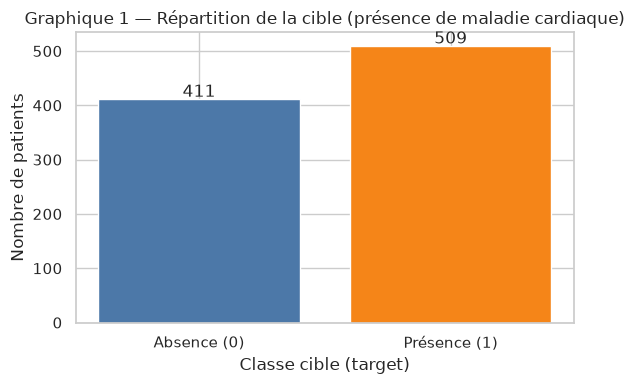

In [12]:
# Graphique 1 (barres) : répartition de la cible binaire
counts = data_clean['target'].value_counts().sort_index()
plt.figure(figsize=(6,4))
bars = plt.bar(['Absence (0)', 'Présence (1)'], counts.values, color=['#4C78A8', '#F58518'])
plt.title('Graphique 1 — Répartition de la cible (présence de maladie cardiaque)')
plt.xlabel('Classe cible (target)')
plt.ylabel('Nombre de patients')
for b in bars:
    plt.text(b.get_x()+b.get_width()/2, b.get_height()+5, int(b.get_height()), ha='center')
plt.tight_layout()
plt.show()

**Interprétation (G1) :** 411 patients sans maladie et 509 avec maladie. Les classes sont relativement équilibrées, ce qui facilite l'apprentissage et l'évaluation des modèles de classification.

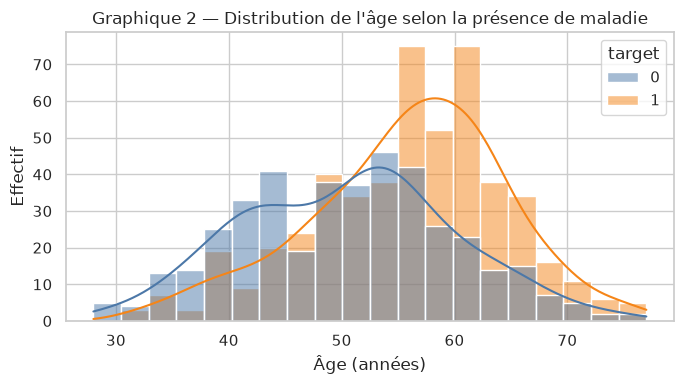

In [13]:
# Graphique 2 (histogramme + densité) : distribution de l'âge selon la cible
plt.figure(figsize=(7,4))
sns.histplot(data=data_clean, x='age', hue='target', bins=20, kde=True, palette=['#4C78A8','#F58518'])
plt.title("Graphique 2 — Distribution de l'âge selon la présence de maladie")
plt.xlabel('Âge (années)')
plt.ylabel('Effectif')
plt.tight_layout()
plt.show()

**Interprétation (G2) :** la proportion de patients malades augmente avec l'âge, mais les distributions se recouvrent : l'âge est un facteur informatif mais insuffisant seul pour prédire la maladie.

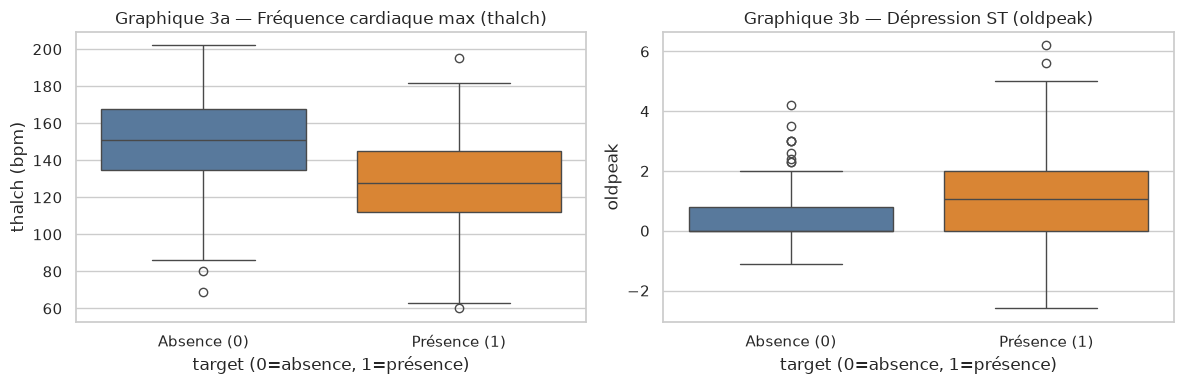

In [14]:
# Graphique 3 (boxplots) : comparaison de variables d'effort selon la cible
fig, axes = plt.subplots(1, 2, figsize=(12,4))
sns.boxplot(data=data_clean, x='target', y='thalch', ax=axes[0], palette=['#4C78A8','#F58518'])
axes[0].set_title('Graphique 3a — Fréquence cardiaque max (thalch)')
axes[0].set_xlabel('target (0=absence, 1=présence)')
axes[0].set_ylabel('thalch (bpm)')
axes[0].set_xticklabels(['Absence (0)','Présence (1)'])
sns.boxplot(data=data_clean, x='target', y='oldpeak', ax=axes[1], palette=['#4C78A8','#F58518'])
axes[1].set_title('Graphique 3b — Dépression ST (oldpeak)')
axes[1].set_xlabel('target (0=absence, 1=présence)')
axes[1].set_ylabel('oldpeak')
axes[1].set_xticklabels(['Absence (0)','Présence (1)'])
plt.tight_layout()
plt.show()

**Interprétation (G3) :** les patients malades ont en médiane une `thalch` plus faible et un `oldpeak` plus élevé, signes associés à une moindre tolérance à l'effort et à l'ischémie.

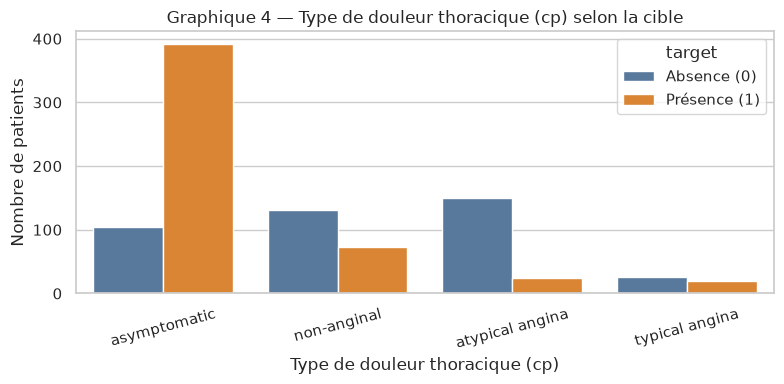

In [15]:
# Graphique 4 (barres groupées / countplot) : type de douleur thoracique vs cible
plt.figure(figsize=(8,4))
order = data_clean['cp'].value_counts().index
sns.countplot(data=data_clean, x='cp', hue='target', order=order, palette=['#4C78A8','#F58518'])
plt.title('Graphique 4 — Type de douleur thoracique (cp) selon la cible')
plt.xlabel('Type de douleur thoracique (cp)')
plt.ylabel('Nombre de patients')
plt.xticks(rotation=15)
plt.legend(title='target', labels=['Absence (0)','Présence (1)'])
plt.tight_layout()
plt.show()

**Interprétation (G4) :** le profil *asymptomatic* est fortement associé aux cas de maladie, tandis que *non-anginal/atypical* apparaissent davantage chez les patients sans maladie. `cp` est une variable potentiellement très discriminante.

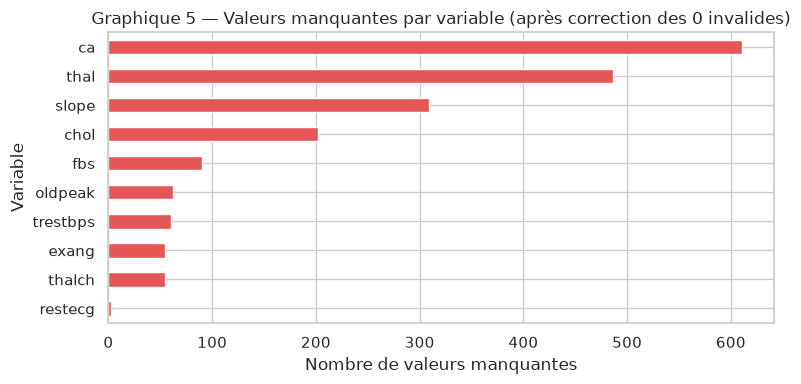

In [16]:
# Graphique 5 (barres horizontales) : valeurs manquantes par variable (qualité des données)
miss = data_clean.isna().sum().sort_values(ascending=True)
miss = miss[miss > 0]
plt.figure(figsize=(8,4))
miss.plot(kind='barh', color='#E45756')
plt.title('Graphique 5 — Valeurs manquantes par variable (après correction des 0 invalides)')
plt.xlabel('Nombre de valeurs manquantes')
plt.ylabel('Variable')
plt.tight_layout()
plt.show()

**Interprétation (G5) :** `ca`, `thal` et `slope` concentrent le plus de manquants (souvent non renseignés hors Cleveland). Ces lacunes justifient une imputation et constituent une limite de l'analyse.

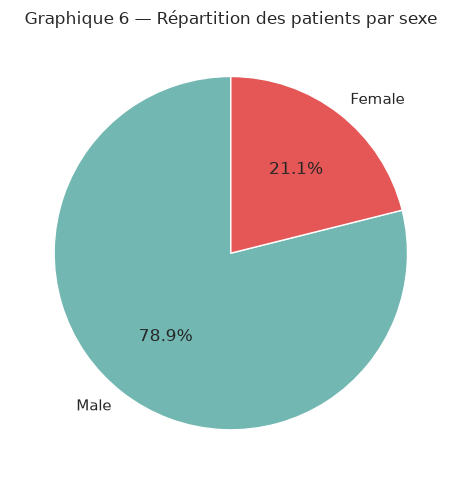

In [17]:
# Graphique 6 (camembert/pie chart, complémentaire) : répartition par sexe
sex_counts = data_clean['sex'].value_counts()
plt.figure(figsize=(5,5))
plt.pie(sex_counts.values, labels=sex_counts.index, autopct='%1.1f%%', startangle=90, colors=['#72B7B2','#E45756'])
plt.title('Graphique 6 — Répartition des patients par sexe')
plt.tight_layout()
plt.show()

**Interprétation (G6) :** l'échantillon est majoritairement masculin (~79%), ce qui peut limiter la représentativité des résultats pour les femmes (biais potentiel).

## D. Relations entre variables et choix des variables
Nous étudions les corrélations (quand c'est possible), produisons une matrice de corrélation, repérons les variables utiles et rappelons qu'**une corrélation ne prouve pas une cause**.

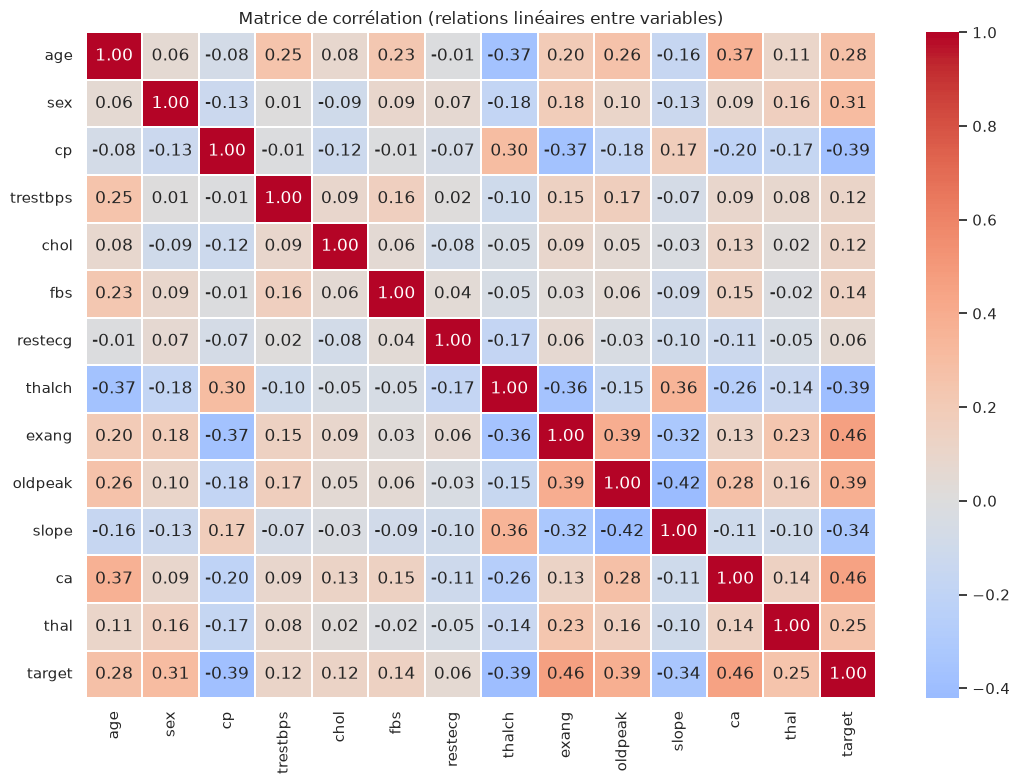

In [18]:
# Préparation pour corrélation : encodage numérique exploratoire des catégories
corr_df = data_clean.copy()
for c in corr_df.select_dtypes(exclude=['number']).columns:
    corr_df[c] = corr_df[c].astype('category').cat.codes.replace(-1, np.nan)

# Exclusion des identifiants/source cible redondante/métadonnée non clinique
corr_df = corr_df.drop(columns=['id', 'dataset', 'num'], errors='ignore')
corr = corr_df.corr(numeric_only=True)

plt.figure(figsize=(11,8))
sns.heatmap(corr, annot=True, fmt='.2f', cmap='coolwarm', center=0, linewidths=0.3)
plt.title('Matrice de corrélation (relations linéaires entre variables)')
plt.tight_layout()
plt.show()

,correlation_avec_target
exang,0.463619
ca,0.455599
thalch,-0.394503
oldpeak,0.385528
cp,-0.385077
slope,-0.337086
sex,0.307284
age,0.282700
thal,0.253260
fbs,0.142565


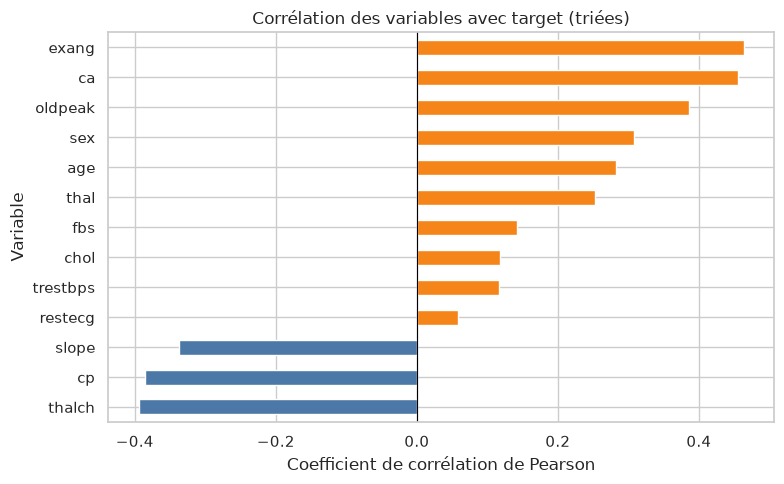

In [19]:
# Corrélation avec la variable cible (repérage des variables utiles)
target_corr = corr['target'].drop(labels=['target']).sort_values(key=lambda s: s.abs(), ascending=False)
display(target_corr.to_frame('correlation_avec_target'))

plt.figure(figsize=(8,5))
target_corr.sort_values().plot(kind='barh', color=np.where(target_corr.sort_values()>0,'#F58518','#4C78A8'))
plt.axvline(0, color='black', linewidth=0.8)
plt.title('Corrélation des variables avec target (triées)')
plt.xlabel('Coefficient de corrélation de Pearson')
plt.ylabel('Variable')
plt.tight_layout()
plt.show()

**Analyse et choix des variables utiles :**
- Variables parmi les plus associées à `target` (exploration, corrélation sur encodage numérique) : `exang`, `ca`, `thalch`, `oldpeak`, `cp`, `slope`, `sex`, `age`, `thal` (associations plausibles médicalement dans ce dataset). Variables plus faiblement associées individuellement : `fbs`, `chol`, `trestbps`, `restecg`.
- Ces résultats, cohérents avec l'EDA, motivent l'utilisation des variables cliniques comme features (tout en ne supprimant pas automatiquement les variables à faible corrélation individuelle, qui peuvent être utiles en modèle non linéaire).
- **Précaution méthodologique :** les variables sont de natures différentes (numériques, binaires, catégorielles nominales/ordinales). Un encodage arbitraire peut influencer le signe des corrélations (ex. `cp`, `slope`). Idéalement, compléter par des méthodes adaptées (Pearson/Spearman pour numériques, Chi-deux / V de Cramér pour catégorielles).
- **Rappel important :** une corrélation mesure une association statistique, **pas une relation de cause à effet**.

## E. Modèle de classification (tâche adaptée)
**Tâche :** classification binaire (prédire la classe `target` : 0/1), adaptée car la variable à prédire est catégorielle.  
**Contraintes respectées :** séparation train/test, `random_state=42`, pipeline anti-fuite de données (prétraitement ajusté sur le train uniquement).  
**Comparaison :** une **baseline de référence** (prédire toujours la classe la plus fréquente) + au moins deux modèles (Régression Logistique, Random Forest, KNN).

In [20]:
# Définition des features (X) et de la cible (y)
# On exclut id (identifiant), dataset (métadonnée), num (source directe de la cible) -> évite la fuite de données
feature_cols = ['age','sex','cp','trestbps','chol','fbs','restecg','thalch','exang','oldpeak','slope','ca','thal']
X = data_clean[feature_cols].copy()
y = data_clean['target'].copy()

print('Features utilisées:', feature_cols)
print('X shape:', X.shape, '| y shape:', y.shape)

Features utilisées: ['age', 'sex', 'cp', 'trestbps', 'chol', 'fbs', 'restecg', 'thalch', 'exang', 'oldpeak', 'slope', 'ca', 'thal']
X shape: (920, 13) | y shape: (920,)


In [21]:
# Séparation entraînement/test (données de test non vues pendant l'apprentissage)
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=RANDOM_STATE, stratify=y
)
print('Train:', X_train.shape, ' Test:', X_test.shape)
print('Répartition y_train:', y_train.value_counts(normalize=True).round(3).to_dict())
print('Répartition y_test :', y_test.value_counts(normalize=True).round(3).to_dict())

Train: (736, 13)  Test: (184, 13)
Répartition y_train: {1: 0.553, 0: 0.447}
Répartition y_test : {1: 0.554, 0: 0.446}


In [22]:
# Prétraitement dans un pipeline (ajusté sur train uniquement -> pas de fuite de données)
numeric_features = X_train.select_dtypes(include=['int64','float64']).columns.tolist()
categorical_features = [c for c in X_train.columns if c not in numeric_features]

numeric_transformer = Pipeline(steps=[
    ('imputer', SimpleImputer(strategy='median')),  # imputation des manquants numériques
    ('scaler', StandardScaler())                    # mise à l'échelle
])
categorical_transformer = Pipeline(steps=[
    ('imputer', SimpleImputer(strategy='most_frequent')),  # imputation des manquants catégoriels
    ('onehot', OneHotEncoder(handle_unknown='ignore'))     # encodage des catégories
])
preprocessor = ColumnTransformer(transformers=[
    ('num', numeric_transformer, numeric_features),
    ('cat', categorical_transformer, categorical_features)
])

print('Numériques:', numeric_features)
print('Catégorielles:', categorical_features)

Numériques: ['age', 'trestbps', 'chol', 'thalch', 'oldpeak', 'ca']
Catégorielles: ['sex', 'cp', 'fbs', 'restecg', 'exang', 'slope', 'thal']


In [23]:
# Définition des modèles : baseline (référence) + modèles de classification
models = {
    'Baseline (classe majoritaire)': DummyClassifier(strategy='most_frequent', random_state=RANDOM_STATE),
    'Régression Logistique': LogisticRegression(max_iter=1000, random_state=RANDOM_STATE),
    'Random Forest': RandomForestClassifier(n_estimators=200, random_state=RANDOM_STATE),
    'KNN (k=7)': KNeighborsClassifier(n_neighbors=7)
}

trained, predictions, probabilities = {}, {}, {}
for name, model in models.items():
    if name == 'Baseline (classe majoritaire)':
        pipe = Pipeline(steps=[('model', model)])  # pas de features nécessaires
        pipe.fit(X_train, y_train)
    else:
        pipe = Pipeline(steps=[('preprocess', preprocessor), ('model', model)])
        pipe.fit(X_train, y_train)  # fit sur train uniquement

    y_pred = pipe.predict(X_test)  # prédiction sur test
    y_proba = pipe.predict_proba(X_test)[:, 1] if hasattr(pipe, 'predict_proba') else y_pred.astype(float)

    trained[name] = pipe
    predictions[name] = y_pred
    probabilities[name] = y_proba
    print(f'OK - {name}')

OK - Baseline (classe majoritaire)
OK - Régression Logistique


OK - Random Forest
OK - KNN (k=7)


In [24]:
# Évaluation des modèles sur le jeu de test
# Métriques demandées pour la classification : accuracy, précision, rappel, F1 (+ matrice de confusion ci-dessous)
# On ajoute aussi RMSE, MAE, R² (compléments) et ROC-AUC (utile pour la classification)
rows = []
for name in models.keys():
    yt = y_test.values
    yp = predictions[name]
    yprob = probabilities[name]
    mse = mean_squared_error(yt, yprob)
    try:
        auc = roc_auc_score(yt, yprob)
    except Exception:
        auc = np.nan
    rows.append({
        'Modèle': name,
        'Accuracy': accuracy_score(yt, yp),
        'Précision': precision_score(yt, yp, zero_division=0),
        'Rappel': recall_score(yt, yp, zero_division=0),
        'F1-score': f1_score(yt, yp, zero_division=0),
        'Matrice de confusion': 'voir ci-dessous',
        'MAE': mean_absolute_error(yt, yprob),
        'RMSE': np.sqrt(mse),
        'R2': r2_score(yt, yprob),
        'ROC-AUC': auc
    })

results_table = pd.DataFrame(rows).set_index('Modèle')
display(results_table.drop(columns=['Matrice de confusion']).round(4))

,Accuracy,Précision,Rappel,F1-score,MAE,RMSE,R2,ROC-AUC
Modèle,,,,,,,,
Baseline (classe majoritaire),0.5543,0.5543,1.0000,0.7133,0.4457,0.6676,-0.8039,0.5000
Régression Logistique,0.8098,0.8190,0.8431,0.8309,0.2634,0.3651,0.4604,0.8895
Random Forest,0.8098,0.8131,0.8529,0.8325,0.2607,0.3547,0.4906,0.9023
KNN (k=7),0.7989,0.7928,0.8627,0.8263,0.2593,0.3771,0.4244,0.8700



Baseline (classe majoritaire): TN=0 FP=82 FN=0 TP=102



Régression Logistique: TN=63 FP=19 FN=16 TP=86



Random Forest: TN=62 FP=20 FN=15 TP=87



KNN (k=7): TN=59 FP=23 FN=14 TP=88


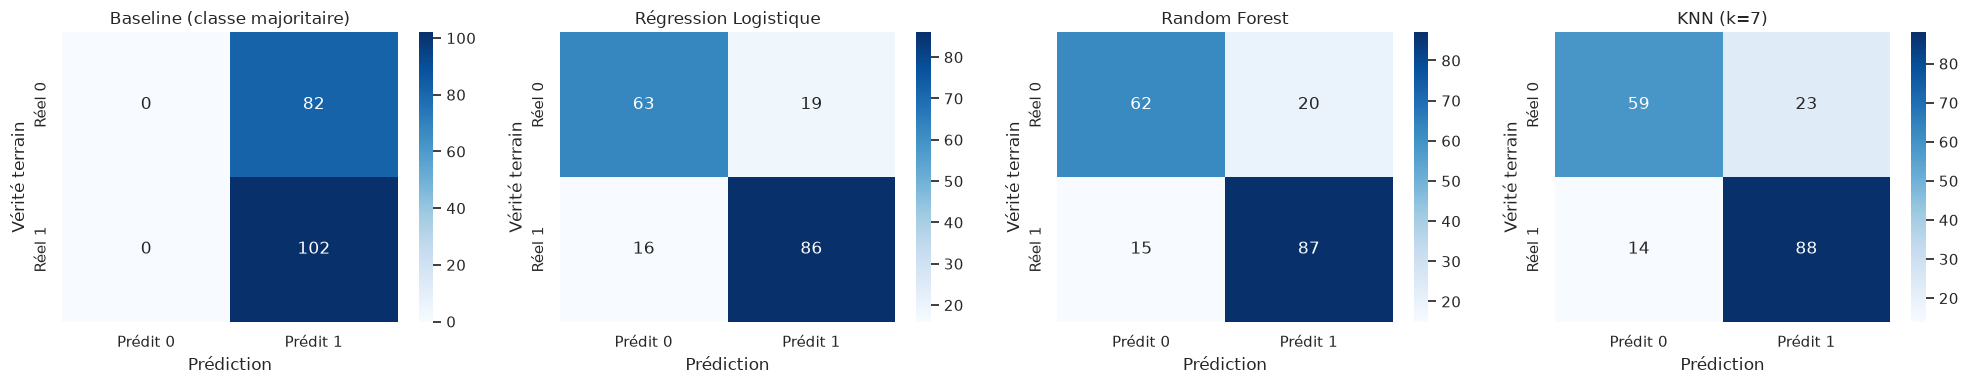


=== Rapport de classification — Baseline (classe majoritaire) ===
              precision    recall  f1-score   support

 Absence (0)       0.00      0.00      0.00        82
Présence (1)       0.55      1.00      0.71       102

    accuracy                           0.55       184
   macro avg       0.28      0.50      0.36       184
weighted avg       0.31      0.55      0.40       184


=== Rapport de classification — Régression Logistique ===
              precision    recall  f1-score   support

 Absence (0)       0.80      0.77      0.78        82
Présence (1)       0.82      0.84      0.83       102

    accuracy                           0.81       184
   macro avg       0.81      0.81      0.81       184
weighted avg       0.81      0.81      0.81       184


=== Rapport de classification — Random Forest ===
              precision    recall  f1-score   support

 Absence (0)       0.81      0.76      0.78        82
Présence (1)       0.81      0.85      0.83       102

    a

In [25]:
# Matrices de confusion et rapports (accuracy, précision, rappel, F1 par classe)
fig, axes = plt.subplots(1, 4, figsize=(20, 4))
for ax, (name, yp) in zip(axes, predictions.items()):
    cm = confusion_matrix(y_test, yp)
    sns.heatmap(cm, annot=True, fmt='d', cmap='Blues', ax=ax,
                xticklabels=['Prédit 0','Prédit 1'], yticklabels=['Réel 0','Réel 1'])
    ax.set_title(name)
    ax.set_xlabel('Prédiction')
    ax.set_ylabel('Vérité terrain')
    tn, fp, fn, tp = cm.ravel()
    print(f"\n{name}: TN={tn} FP={fp} FN={fn} TP={tp}")
plt.tight_layout()
plt.show()

for name, yp in predictions.items():
    print(f"\n=== Rapport de classification — {name} ===")
    print(classification_report(y_test, yp, target_names=['Absence (0)','Présence (1)'], zero_division=0))

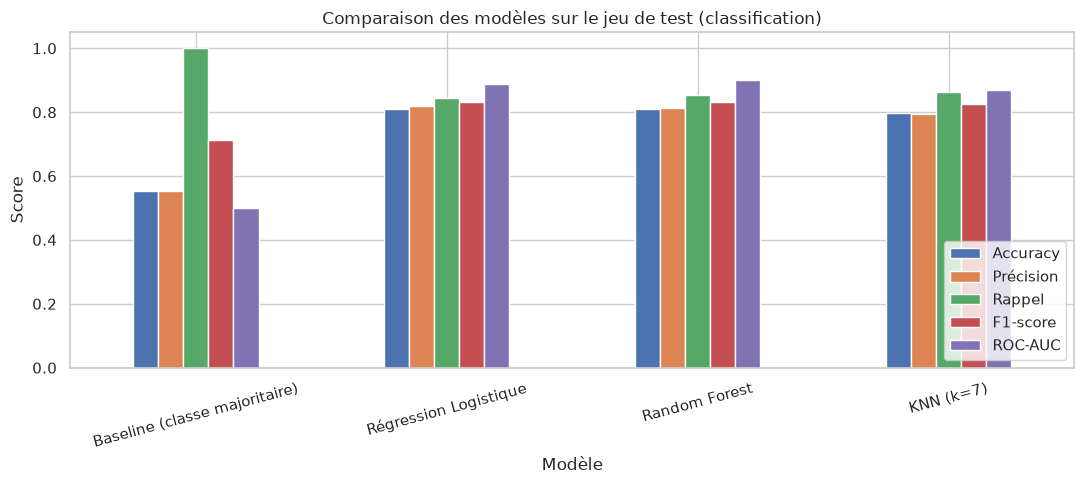

In [26]:
# Comparaison visuelle des modèles (au moins deux modèles comparés + baseline)
comp_metrics = results_table.drop(columns=['Matrice de confusion'])[['Accuracy','Précision','Rappel','F1-score','ROC-AUC']].astype(float)
comp_metrics.plot(kind='bar', figsize=(11,5))
plt.title('Comparaison des modèles sur le jeu de test (classification)')
plt.ylabel('Score')
plt.ylim(0, 1.05)
plt.xticks(rotation=15)
plt.legend(loc='lower right')
plt.tight_layout()
plt.show()

**Interprétation (modèles) :** la baseline (classe majoritaire) sert de référence minimale. Les modèles appris (Régression Logistique, Random Forest, KNN) doivent la surpasser sur les métriques pertinentes. On compare leurs compromis précision/rappel/F1 et la matrice de confusion (notamment les faux négatifs).

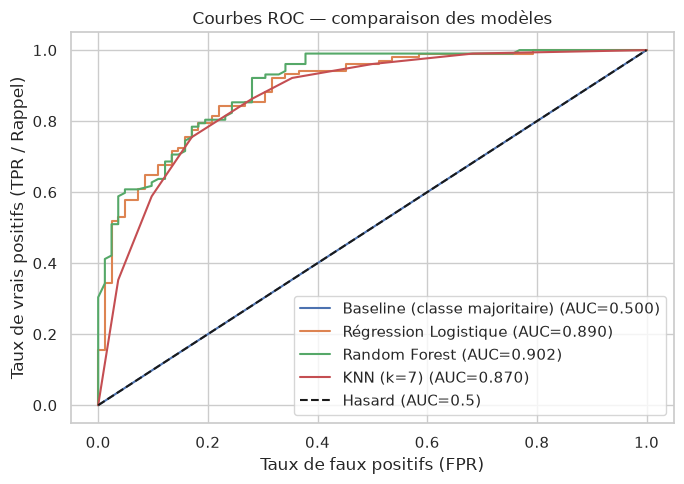

In [27]:
# Courbes ROC (comparaison de la capacité de discrimination des modèles)
plt.figure(figsize=(7,5))
for name in models.keys():
    fpr, tpr, _ = roc_curve(y_test, probabilities[name])
    try:
        auc = roc_auc_score(y_test, probabilities[name])
    except Exception:
        auc = np.nan
    plt.plot(fpr, tpr, label=f"{name} (AUC={auc:.3f})")
plt.plot([0,1],[0,1],'k--', label='Hasard (AUC=0.5)')
plt.xlabel('Taux de faux positifs (FPR)')
plt.ylabel('Taux de vrais positifs (TPR / Rappel)')
plt.title('Courbes ROC — comparaison des modèles')
plt.legend(loc='lower right')
plt.tight_layout()
plt.show()

**Interprétation (ROC/AUC) :** plus la courbe est proche du coin supérieur gauche et plus l'AUC est élevée, meilleure est la capacité du modèle à distinguer malades et sains. Les modèles appris sont comparés à la baseline/référence.

## F. Interprétation et cas de test
Nous présentons des prédictions sur des exemples du jeu de test (données non vues), comparons aux vraies valeurs, et commentons erreurs, limites et risques de mauvaise interprétation.

In [28]:
# Choix du meilleur modèle (hors baseline) selon le F1-score
model_metrics = results_table.drop(index=['Baseline (classe majoritaire)'], errors='ignore')
best_name = model_metrics['F1-score'].astype(float).idxmax()
best_pred = predictions[best_name]
best_proba = probabilities[best_name]
print('Modèle retenu (meilleur F1 hors baseline):', best_name)

# Comparaison valeur réelle vs valeur prédite sur quelques exemples du test
sample = X_test.reset_index(drop=True).copy()
sample['valeur_reelle'] = y_test.values
sample['valeur_predite'] = best_pred
sample['proba_maladie'] = np.round(best_proba, 4)
sample['correct'] = sample['valeur_reelle'] == sample['valeur_predite']
sample['analyse'] = np.where(
    sample['correct'], 'Correct',
    np.where((sample['valeur_reelle']==1) & (sample['valeur_predite']==0),
             'Faux négatif (malade non détecté)', 'Faux positif (fausse alerte)')
)
display(sample[['age','sex','cp','thalch','oldpeak','exang','valeur_reelle','valeur_predite','proba_maladie','analyse']].head(15))

Modèle retenu (meilleur F1 hors baseline): Random Forest


,age,sex,cp,thalch,oldpeak,exang,valeur_reelle,valeur_predite,proba_maladie,analyse
0,49,Male,asymptomatic,170.0,0.0,False,1,0,0.405,Faux négatif (malade non détecté)
1,61,Male,asymptomatic,135.0,4.0,True,1,1,0.860,Correct
2,55,Male,asymptomatic,73.0,2.0,False,1,1,0.870,Correct
3,65,Male,asymptomatic,140.0,4.0,True,1,1,0.970,Correct
4,69,Male,non-anginal,NaN,NaN,NaN,0,1,0.685,Faux positif (fausse alerte)
5,59,Male,non-anginal,120.0,1.0,True,0,1,0.850,Faux positif (fausse alerte)
6,71,Female,asymptomatic,125.0,1.6,False,0,0,0.350,Correct
7,50,Male,asymptomatic,121.0,2.0,True,1,1,1.000,Correct
8,48,Male,atypical angina,118.0,0.0,False,0,0,0.030,Correct
9,38,Female,asymptomatic,166.0,2.8,False,1,1,0.520,Correct


Bilan Random Forest: TN=62, FP=20, FN=15, TP=87
Accuracy sur test: 0.810


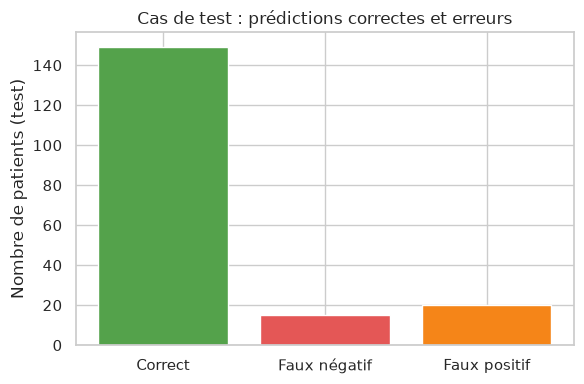

In [29]:
# Bilan des erreurs sur le test
cm = confusion_matrix(y_test, best_pred)
tn, fp, fn, tp = cm.ravel()
print(f"Bilan {best_name}: TN={tn}, FP={fp}, FN={fn}, TP={tp}")
print(f"Accuracy sur test: {accuracy_score(y_test,best_pred):.3f}")

err_df = pd.DataFrame({'Type': ['Correct','Faux négatif','Faux positif'],
                       'Nombre': [(y_test.values==best_pred).sum(), fn, fp]})
plt.figure(figsize=(6,4))
plt.bar(err_df['Type'], err_df['Nombre'], color=['#54A24B','#E45756','#F58518'])
plt.title('Cas de test : prédictions correctes et erreurs')
plt.ylabel('Nombre de patients (test)')
plt.tight_layout()
plt.show()

**Interprétation des cas de test et erreurs :**
- La comparaison **réelle vs prédite** montre le comportement concret du modèle sur des patients non vus.
- **Faux négatifs** : malades prédits sains → risque de retard de prise en charge (erreur la plus critique en dépistage).
- **Faux positifs** : sains prédits malades → fausses alertes, examens/stress inutiles.
- **Risques de mauvaise interprétation :** sur-confiance dans une probabilité, oubli des biais du dataset (centres, manquants, sexe majoritaire), confusion corrélation/causalité, et utilisation hors contexte clinique. Le modèle est une aide, pas un diagnostic.

**Limites :** données anciennes/multi-centres, 920 observations, variables incomplètes (`ca/thal/slope`), pas de validation externe, généralisation incertaine.

## G. Conclusion et recommandations

### Résumé des principaux résultats
- **Données :** 920 patients, 16 variables (UCI Heart Disease, 4 centres). Cible binaire `target` (maladie si `num>0`) relativement équilibrée.
- **Préparation :** doublons inexistants, correction des valeurs invalides (`chol/trestbps==0`), imputation des manquants, encodage/scaling via pipeline, split train/test stratifié (80/20, `random_state=42`) sans fuite de données.
- **Analyse :** ≥ 5 graphiques interprétés, matrice de corrélation et variables utiles identifiées (rappel : corrélation ≠ causalité).
- **Modélisation :** baseline + plusieurs modèles de classification comparés (Régression Logistique, Random Forest, KNN) avec accuracy, précision, rappel, F1 et matrices de confusion (et métriques complémentaires RMSE/MAE/R²/ROC-AUC).

### Modèle le plus adapté
Le modèle retenu est celui présentant le meilleur compromis sur le test (notamment **F1-score** et **rappel**, importants pour limiter les faux négatifs), tout en surpassant la baseline. (Voir le tableau de comparaison et le bilan de confusion ci-dessus pour le modèle exact sélectionné dans cette exécution.)

### Limites des données et du modèle
- Manquants importants (`ca`, `thal`, `slope`) et hétérogénéité entre centres.
- Dataset ancien, taille modeste, biais de représentativité (ex. sexe majoritaire masculin).
- Pas de validation externe ni optimisation exhaustive ; performances non généralisables sans études complémentaires.

### Recommandations concrètes pour le secteur (santé)
1. **Utiliser le modèle comme outil d'aide au pré-triage uniquement**, avec validation systématique par un professionnel de santé (jamais de décision automatisée seule), en privilégiant la détection des cas à risque (rappel élevé).
2. **Améliorer la qualité et la représentativité des données** (compléter les variables manquantes, collecter des données récentes/multi-populations, équilibrer les sous-groupes) avant toute utilisation opérationnelle.
3. *(Complémentaire)* Mettre en place un suivi des performances et des biais (réévaluation régulière, calibration, seuils adaptés au contexte clinique).

## H. Éthique et responsabilité
- **Qui subit les conséquences d'une erreur du modèle ?** Les patients (faux négatif : retard de diagnostic/prise en charge ; faux positif : anxiété, examens invasifs ou coûteux inutiles), ainsi que les professionnels de santé et l'établissement (responsabilité, perte de confiance).
- **Risques pour les libertés, la vie privée ou l'image :** même si le dataset UCI est public et anonymisé, une mauvaise utilisation de modèles de santé peut conduire à une discrimination/biais (selon sexe, origine, centre), à une surveillance ou décision injustifiée, et nuire à l'image de l'institution en cas d'erreur.
- **Vérification humaine à prévoir :** toute prédiction doit être interprétée par un clinicien qualifié ; le système doit rester une **aide à la décision** avec possibilité de contestation, traçabilité des résultats et validation humaine avant action.
- **Bonnes pratiques :** transparence sur les limites, respect des licences des données, protection des données sensibles, et évaluation continue des biais/performances.

## Export des livrables de données (fichier nettoyé et tableaux)
Export du jeu de données nettoyé/préparé de base et des tableaux de résultats pour les rendre disponibles en fichiers.

In [30]:
# Export du fichier nettoyé (données préparées de base) et des résultats
import os

# Sauvegarde du dataset nettoyé (avec corrections 0->NaN et cible target)
data_clean.to_csv('heart_disease_cleaned.csv', index=False)
print('Fichier exporté : heart_disease_cleaned.csv', data_clean.shape)

# Sauvegarde du tableau comparatif des métriques (résultats sur le jeu de test)
results_export = results_table.drop(columns=['Matrice de confusion'], errors='ignore').round(6)
results_export.to_csv('resultats_modeles.csv')
print('Fichier exporté : resultats_modeles.csv')

# Sauvegarde des exemples réel vs prédit (meilleur modèle)
sample_export = sample[['age','sex','cp','thalch','oldpeak','exang','valeur_reelle','valeur_predite','proba_maladie','analyse']].copy()
sample_export.to_csv('exemples_reel_vs_predit.csv', index=False)
print('Fichier exporté : exemples_reel_vs_predit.csv')

Fichier exporté : heart_disease_cleaned.csv (920, 17)
Fichier exporté : resultats_modeles.csv
Fichier exporté : exemples_reel_vs_predit.csv


## Annexe — Reproductibilité et exécution
- **random_state fixé à 42** pour la séparation et les modèles.
- Le notebook s'exécute de haut en bas (**Restart & Run All**) sans erreur, avec les dépendances listées dans `requirements.txt` (pandas, numpy, matplotlib, seaborn, scikit-learn, jupyter, etc.).
- Fichiers du projet : `heart_disease_uci.csv` (données), `heart_disease_project.ipynb` (notebook), `app.py` (dashboard Streamlit), `rapport_projet.md/.pdf` (rapport).